# Julia から Wolfram Engine を呼び出す — 複素数平面を Julia で使う

[MathLink.jl](https://github.com/JuliaInterop/MathLink.jl) を使って Julia から Wolfram Engine を呼び出します（積分・微分・方程式・数列・確率編の続き）。

Julia は複素数を標準で扱えます（虚数単位は `im`）。Wolfram の**厳密な値**を Julia の複素数として受け取り，計算と図示に使います。

- 複素数の計算・絶対値・偏角 → 厳密値（$\frac{\pi}{3}$ など）を受け取る
- 極形式とド・モアブルの定理
- 方程式 $z^n = \alpha$ → 厳密解を **Julia の複素数の配列**にして，複素数平面に描く
- 回転・図形への応用
- 軌跡（アポロニウスの円など）→ $x, y$ の方程式に直して図示する
- 数式は $\LaTeX$ 組版（TraditionalForm 相当）で表示する

**注意**：無料版 Wolfram Engine は同時に起動できるカーネル数に上限があります。他のノートブックや `wolframscript` が動いたままだと接続に失敗するので，使い終わったカーネルは停止してください。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。初回だけパッケージを追加します（追加済みなら次のセルは実行不要）。

In [1]:
# import Pkg; Pkg.add(["MathLink", "Plots"])

In [2]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数（表示・変換）
using Plots

## 1. 基本：Wolfram と Julia の複素数

虚数単位は，Wolfram では `I`，Julia では `im` です。

In [3]:
weval(W`(1 + 2 I) (3 - I)`)

W`Complex[5, 5]`

In [4]:
weval(W`(1 + 2 I)/(3 - I)`)          # 厳密な分数のまま

W`Complex[Rational[1, 10], Rational[7, 10]]`

In [5]:
# Julia の複素数（分数 // を使えば Julia でも厳密に計算できる）
(1 + 2im) * (3 - im), (1 + 2im) / (3 - im), (1 + 2im) // (3 - im)

(5 + 5im, 0.1 + 0.7000000000000001im, 1//10 + 7//10*im)

累乗根や根号を含む結果は，Wolfram では $(-1)^{2/3}$ のような形で返ることがあります。  
`ComplexExpand` をかけると $a + bi$ の形になります。

In [6]:
weval(W`z /. Solve[z^3 == 1, z]`)

W`List[1, Times[-1, Power[-1, Rational[1, 3]]], Power[-1, Rational[2, 3]]]`

In [7]:
weval(W`ComplexExpand[z /. Solve[z^3 == 1, z]]`)

W`List[1, Plus[Rational[-1, 2], Times[Complex[0, Rational[-1, 2]], Power[3, Rational[1, 2]]]], Plus[Rational[-1, 2], Times[Complex[0, Rational[1, 2]], Power[3, Rational[1, 2]]]]]`

## 2. きれいに表示するための関数

`calc("Wolfram の式")` は，入力した式と評価結果（$a+bi$ の形）を「左辺 = 右辺」で表示し，結果を返します。

In [8]:
# TeXForm の出力を見やすく整える（共役は上線，Re・Im は立体）
function jtex(s)
    s = replace(s, r"\\left\((.*?)\\right\)\^\*" => s"\\overline{\1}")
    s = replace(s, r"\(([^()]*)\)\^\*" => s"\\overline{\1}", r"([a-zA-Z]|\\\w+)\^\*" => s"\\overline{\1}")
    replace(s, "\\Re" => "\\mathrm{Re}", "\\Im" => "\\mathrm{Im}")
end

# Wolfram 言語の文字列 → 評価せずに LaTeX 文字列（入力した形のまま表示する）
texheld(s::AbstractString) = jtex(heldtex(s))

# 「入力した式 = 評価結果」を表示して，結果（Wolfram の式）を返す
#   結果は ComplexExpand で a + b i の形にする。then="TrigReduce" などで後処理を追加できる。
function calc(cmd::AbstractString; then="")
    res = weval(MathLink.parseexpr("ComplexExpand[$cmd]"))
    isempty(then) || (res = weval(W"ComplexExpand"(MathLink.WSymbol(then)(res))))
    showtex(texheld(cmd) * " = " * jtex(tex(res)))
    return res
end

calc (generic function with 1 method)

In [9]:
calc("(1 + 2 I)/(3 - I)")
calc("Conjugate[3 + 4 I]")
calc("Abs[3 + 4 I]")
calc("Arg[1 + Sqrt[3] I]")
calc("(Sqrt[3] + I)^6");

## 3. Wolfram の式を Julia の式・関数に変換する

変換の関数は，共通ファイル `wolfram_common.jl` にまとめてあります（0 節の `include` で読み込み済み）。

- `to_expr(w)`：Wolfram の式 → Julia の式（`Expr`）
- `to_value(w)`：Wolfram の式 → Julia の値
- `to_function(w, :x, ...)`：Wolfram の式 → Julia の関数
- 対応表 `WFUNC`（Wolfram の関数名 → Julia の関数名）に無い関数が出てきたら，`WFUNC["名前"] = :Juliaの関数名` で追加できます。

このノートブックで特に使う変換：

- `Complex[a, b]` → `complex(a, b)`，`I` → `im`
- `Abs`, `Arg`, `Re`, `Im`, `Conjugate` → `abs`, `angle`, `real`, `imag`, `conj`
- 実部・虚部が有理数なら，Julia でも分数のまま厳密（`1//10 + 7//10*im`）

In [10]:
qw = calc("(1 + 2 I)/(3 - I)")
q  = to_value(qw)
@show q typeof(q)                    # 実部・虚部が分数のまま
@show q * (3 - im);                  # Julia で検算（= 1 + 2i）

q = 1//10 + 7//10*im
typeof(q) = Complex{Rational{Int64}}
q * (3 - im) = 1//1 + 2//1*im


### 複素数平面に描くための関数（Julia 側）

In [11]:
# 複素数平面（実軸・虚軸が原点で交わる，縦横比 1）
zplane(lim=2.5; kw...) = plot(; aspect_ratio=1, xlims=(-lim, lim), ylims=(-lim, lim),
                               framestyle=:origin, xlabel="Re", ylabel="Im", legend=:topright, kw...)

zscatter!(zs; kw...) = scatter!(real.(float.(zs)), imag.(float.(zs)); kw...)      # 点を打つ
zpath!(zs; kw...)    = plot!(real.(float.(zs)), imag.(float.(zs)); kw...)         # 折れ線で結ぶ
zcircle!(c=0, r=1; kw...) = zpath!([c + r * cis(t) for t in range(0, 2π; length=201)]; kw...)   # 円
zpolygon!(zs; kw...) = zpath!([zs; zs[1]]; kw...)                                 # 多角形（閉じた折れ線）

zpolygon! (generic function with 1 method)

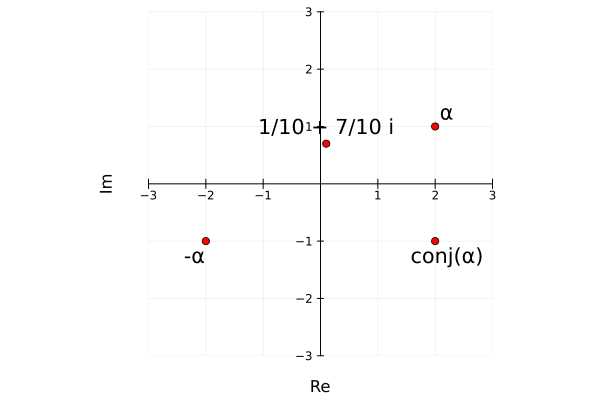

In [12]:
α, β = 2 + im, to_value(qw)

zplane(3)
zscatter!([α, conj(α), -α, β]; label="", color=:red)
annotate!([(2.2, 1.25, "α"), (2.2, -1.25, "conj(α)"), (-2.2, -1.25, "-α"), (0.1, 1.0, "1/10 + 7/10 i")])

## 4. 絶対値・偏角・極形式

`polar("複素数")` は極形式 $r(\cos\theta + i\sin\theta)$ を表示し，$(r, \theta)$ を Julia の値で返します。

In [13]:
function polar(z::AbstractString)
    rw = weval(MathLink.parseexpr("Simplify[Abs[$z]]"))
    θw = weval(MathLink.parseexpr("Simplify[Arg[$z]]"))
    θt = tex(θw)
    θp = startswith(θt, "-") ? "\\left(" * θt * "\\right)" : θt          # 負の角にはかっこを付ける
    rt = rw == 1 ? "" : tex(rw)                                          # r = 1 のときは省く
    showtex(texheld(z) * " = " * rt * "\\left(\\cos " * θp * " + i \\sin " * θp * "\\right)" *
            "\\qquad \\left(r = " * tex(rw) * ",\\ \\theta = " * θt * "\\right)")
    return to_value(rw), to_value(θw)
end

polar (generic function with 1 method)

In [14]:
r, θ = polar("1 + Sqrt[3] I")
polar("-1 - I")
polar("-2 I")
polar("(1 + Sqrt[3] I)/(1 + I)")

r, θ, abs(1 + sqrt(3)im), angle(1 + sqrt(3)im)      # Julia の abs, angle と一致（θ = π/3 は無理数として厳密）

(2, 1.0471975511965976, 2.0, 1.0471975511965976)

Julia では `cis(θ)` が $\cos\theta + i\sin\theta$ です。極形式から元の複素数に戻して確かめます。

In [15]:
r * cis(θ), 1 + sqrt(3)im

(1.0000000000000002 + 1.7320508075688772im, 1.0 + 1.7320508075688772im)

## 5. ド・モアブルの定理

$(\cos\theta + i\sin\theta)^n = \cos n\theta + i\sin n\theta$

In [16]:
calc("(1 + I)^10")
calc("(Sqrt[3] + I)^6")
calc("((1 + Sqrt[3] I)/2)^100")
calc("(1 - I)^(-8)")
calc("(Cos[Pi/12] + I Sin[Pi/12])^4");

In [17]:
# Julia でも計算できる（整数どうしなら厳密，根号が入ると近似値）
(1 + im)^10, (sqrt(3) + im)^6, ((1 + sqrt(3)im) / 2)^100

(0 + 32im, -63.99999999999997 - 1.4210854715202004e-14im, -0.5 - 0.8660254037844322im)

### 3 倍角・5 倍角の公式を導く

$(\cos t + i\sin t)^3$ を展開した実部・虚部が，$\cos 3t$，$\sin 3t$ を $\cos t$，$\sin t$ で表す公式になります。

In [18]:
calc("(Cos[t] + I Sin[t])^3")
calc("(Cos[t] + I Sin[t])^3"; then="TrigReduce")       # まとめ直すと cos 3t + i sin 3t
c3w = calc("Re[(Cos[t] + I Sin[t])^3]")
s3w = calc("Im[(Cos[t] + I Sin[t])^3]")
calc("Re[(Cos[t] + I Sin[t])^5]");

In [19]:
c3 = to_function(c3w, :t)
s3 = to_function(s3w, :t)
t0 = 0.7
(c3(t0), cos(3t0)), (s3(t0), sin(3t0))                 # Julia で検算

((-0.5048461045998573, -0.5048461045998571), (0.8632093666488739, 0.8632093666488739))

## 6. 方程式 $z^n = \alpha$ → 解を複素数平面に描く

`csolve(方程式)` は解を $a + bi$ の形で表示し，`(Wolfram の式, Julia の複素数の配列)` を返します。

In [20]:
function csolve(eq::AbstractString, var::AbstractString="z")
    res = weval(MathLink.parseexpr("ComplexExpand[$var /. Solve[$eq, $var]]"))
    res isa MathLink.WExpr && res.head == W"List" || error("Solve では解けませんでした。")
    if occursin("Root[", string(res))                   # 根号で簡単に表せない解は数値にする
        res = weval(W"N"(res))
        showtex(texheld(eq) * "\\iff $var \\approx " * join(tex.(res.args), ",\\ \\ "))
    else
        showtex(texheld(eq) * "\\iff $var = " * join(jtex.(tex.(res.args)), ",\\ \\ "))
    end
    return res, to_value(res)
end

csolve (generic function with 2 methods)

In [21]:
_, z3 = csolve("z^3 == 1")
z3

3-element Vector{ComplexF64}:
  1.0 + 0.0im
 -0.5 - 0.8660254037844386im
 -0.5 + 0.8660254037844386im

In [22]:
# 検算：3 乗すると 1，和は 0
z3 .^ 3, sum(z3)

(ComplexF64[1.0 + 0.0im, 0.9999999999999998 - 1.1102230246251565e-16im, 0.9999999999999998 + 1.1102230246251565e-16im], 0.0 + 0.0im)

**1 の $n$ 乗根は，単位円に内接する正 $n$ 角形の頂点**になります。

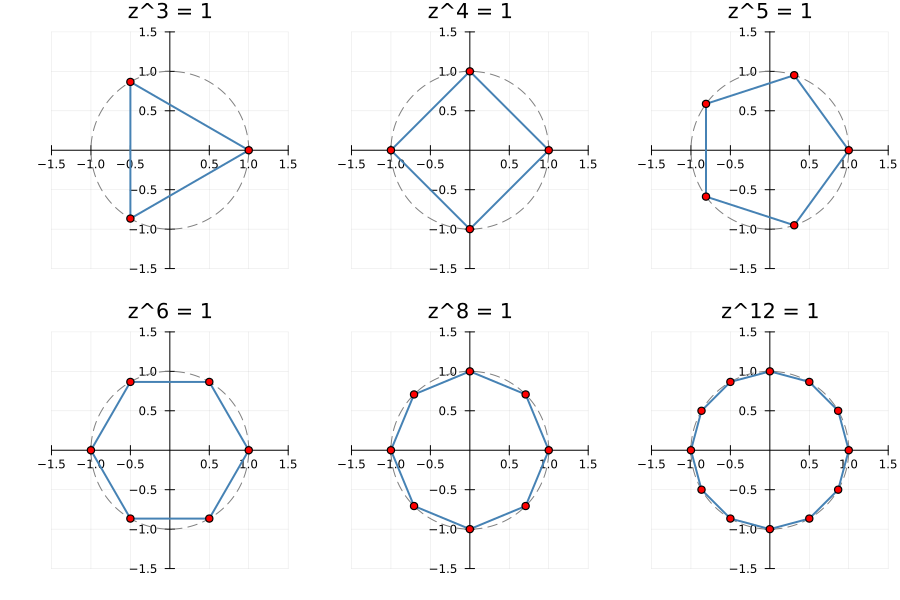

In [23]:
plots = map((3, 4, 5, 6, 8, 12)) do n
    _, zs = csolve("z^$n == 1")
    zs = sort(zs; by=angle)                             # 偏角の順に並べて多角形にする
    zplane(1.5; title="z^$n = 1", legend=false, xlabel="", ylabel="")
    zcircle!(; color=:gray, ls=:dash)
    zpolygon!(zs; color=:steelblue, lw=2)
    zscatter!(zs; color=:red)
end
plot(plots...; layout=(2, 3), size=(900, 600))

$n = 7$ のように根号で簡単に書けない場合は，三角関数で表されます。

In [24]:
_, z7 = csolve("z^7 == 1")
maximum(abs.(z7 .^ 7 .- 1))                             # 検算（誤差の最大値）

3.7238012298709097e-16

### 1 の 3 乗根 $\omega$

In [25]:
ω = "((-1 + Sqrt[3] I)/2)"
calc("$ω^2")
calc("$ω^3")
calc("1 + $ω + $ω^2")
calc("Conjugate[$ω]")
calc("1/$ω");

### いろいろな方程式

In [26]:
_, w1 = csolve("z^3 == 8 I")
_, w2 = csolve("z^2 == I")
_, w3 = csolve("z^4 == -4")
_, w4 = csolve("z^2 == 3 + 4 I")
_, w5 = csolve("z^2 - (3 + I) z + 4 + 3 I == 0")       # 複素数係数の 2 次方程式
_, w6 = csolve("z^4 + z^2 + 1 == 0");

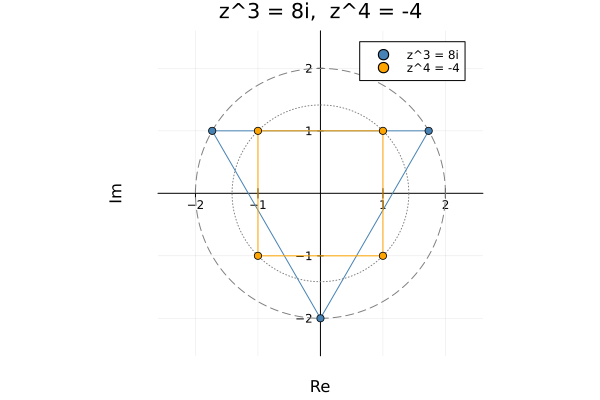

In [27]:
zplane(2.6; title="z^3 = 8i,  z^4 = -4")
zcircle!(0, 2; color=:gray, ls=:dash, label="")
zcircle!(0, sqrt(2); color=:gray, ls=:dot, label="")
zpolygon!(sort(w1; by=angle); color=:steelblue, label="")
zscatter!(w1; color=:steelblue, label="z^3 = 8i")
zpolygon!(sort(w3; by=angle); color=:orange, label="")
zscatter!(w3; color=:orange, label="z^4 = -4")

## 7. 回転と図形

点 $z$ を点 $\alpha$ のまわりに $\theta$ だけ回転した点は $\ (z - \alpha)(\cos\theta + i\sin\theta) + \alpha$ です。

In [28]:
# 厳密な計算（Wolfram）
pw1 = calc("(2 + I) (Cos[Pi/3] + I Sin[Pi/3])")                       # 原点のまわりに π/3 回転
pw2 = calc("((4 + I) - (1 + I)) (Cos[Pi/3] + I Sin[Pi/3]) + (1 + I)") # 点 1+i のまわりに π/3 回転

# 同じことを Julia の関数で（近似値）
rot(z, θ; center=0) = (z - center) * cis(θ) + center
@show to_value(pw1) rot(2 + im, π / 3)
@show to_value(pw2) rot(4 + im, π / 3; center=1 + im);

to_value(pw1) = 0.1339745962155614 + 2.232050807568877im
rot(2 + im, π / 3) = 0.13397459621556163 + 2.232050807568877im
to_value(pw2) = 2.5 + 3.598076211353316im
rot(4 + im, π / 3; center = 1 + im) = 2.5000000000000004 + 3.598076211353316im


**正三角形の第 3 の頂点**：$A(1+i)$，$B(4+i)$ に対し，$B$ を $A$ のまわりに $\pm\frac{\pi}{3}$ 回転した点が $C$ です。

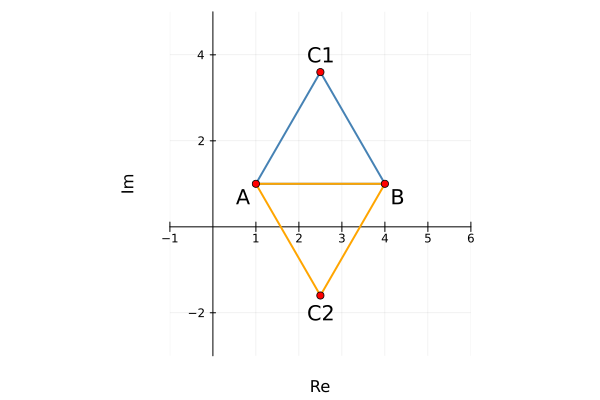

In [29]:
A, B = 1 + im, 4 + im
C1 = to_value(pw2)
C2 = to_value(calc("((4 + I) - (1 + I)) (Cos[-Pi/3] + I Sin[-Pi/3]) + (1 + I)"))

zplane(5; xlims=(-1, 6), ylims=(-3, 5))
zpolygon!([A, B, C1]; lw=2, color=:steelblue, label="")
zpolygon!([A, B, C2]; lw=2, color=:orange, label="")
zscatter!([A, B, C1, C2]; color=:red, label="")
annotate!([(0.7, 0.7, "A"), (4.3, 0.7, "B"), (2.5, 4.0, "C1"), (2.5, -2.0, "C2")])

In [30]:
abs(B - A), abs(C1 - B), abs(A - C1)                    # 3 辺の長さが等しい

(3.0, 3.0, 3.0)

**図形を回転・拡大する**：正方形の各頂点に $\alpha = \sqrt2\left(\cos\frac{\pi}{4} + i\sin\frac{\pi}{4}\right) = 1 + i$ を掛けると，$\frac{\pi}{4}$ 回転して $\sqrt2$ 倍に拡大されます。

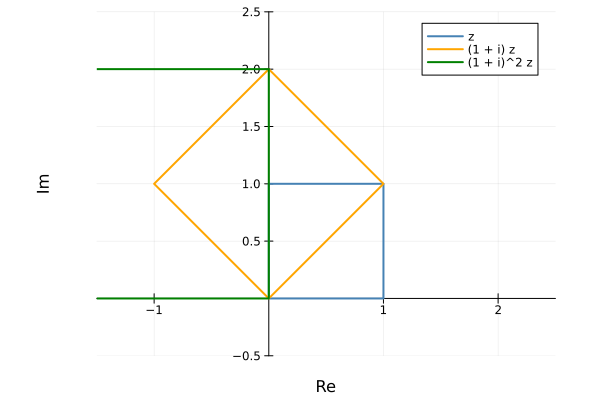

In [31]:
polar("1 + I")
square = [1, 1 + im, im, 0]

zplane(2.5; xlims=(-1.5, 2.5), ylims=(-0.5, 2.5))
zpolygon!(square; lw=2, color=:steelblue, label="z")
zpolygon!(square .* (1 + im); lw=2, color=:orange, label="(1 + i) z")
zpolygon!(square .* (1 + im)^2; lw=2, color=:green, label="(1 + i)^2 z")

### 三角形の形状を調べる

3 点 $A(\alpha)$，$B(\beta)$，$C(\gamma)$ に対し，$\dfrac{\gamma - \alpha}{\beta - \alpha}$ の絶対値と偏角から，$AC : AB$ と $\angle BAC$ がわかります。

In [32]:
# A(1 + i), B(3 + i), C(2 + (1 + √3) i)
ratio = "((2 + (1 + Sqrt[3]) I) - (1 + I))/((3 + I) - (1 + I))"
calc(ratio)
polar(ratio)                         # 絶対値 1，偏角 π/3 → AB = AC，∠A = π/3 → 正三角形

(1, 1.0471975511965976)

In [33]:
# A(0), B(2 + i), C(1 + 3i)
ratio2 = "(1 + 3 I)/(2 + I)"
calc(ratio2)
polar(ratio2)                        # 絶対値 √2，偏角 π/4 → AC = √2 AB，∠A = π/4 → ∠B = π/2 の直角二等辺三角形

(1.4142135623730951, 0.7853981633974483)

## 8. 軌跡

$z = x + yi$（$x, y$ は実数）とおいて，条件を $x, y$ の方程式に直します。  
`locus(条件)` は方程式を表示し，`(Wolfram の方程式, F(x, y) = 左辺 - 右辺 の Julia 関数)` を返します。

In [34]:
function locus(cond::AbstractString)
    # （左辺）-（右辺）を x, y の式に展開する
    Fw  = weval(MathLink.parseexpr("Expand[Subtract @@ ComplexExpand[($cond) /. z -> x + I y]]"))
    eqw = W"Equal"(Fw, 0)
    showtex(texheld(cond) * "\\iff " * tex(eqw))
    return eqw, to_function(Fw, :x, :y)
end

# 軌跡が円のとき，中心と半径を求める（図形の x, y の範囲から計算する）
function circle_of(eqw)
    bw = weval(W"RegionBounds"(W"ImplicitRegion"(eqw, W"List"(W"x", W"y"))))     # {{x1, x2}, {y1, y2}}
    (x1, x2), (y1, y2) = bw.args[1].args, bw.args[2].args
    half(u) = W"Times"(W"Rational"(1, 2), u)
    cw = weval(W"Plus"(half(W"Plus"(x1, x2)), W"Times"(W"Complex"(0, 1), half(W"Plus"(y1, y2)))))   # 中心
    rw = weval(half(W"Plus"(x2, W"Times"(-1, x1))))                                                # 半径
    showtex("\\text{中心 } " * tex(cw) * ",\\quad \\text{半径 } " * tex(rw))
    return to_value(cw), to_value(rw)
end

# F(x, y) = 0 の曲線を描く
function zlocus!(F; lim=4, kw...)
    g = range(-lim, lim; length=400)
    contour!(g, g, (x, y) -> F(x, y); levels=[0.0], colorbar=false, kw...)
end

zlocus! (generic function with 1 method)

**アポロニウスの円**：2 点 $1$，$-1$ からの距離の比が $2 : 1$ である点の軌跡。条件は 2 乗して与えます。

In [35]:
eqw, F = locus("Abs[z - 1]^2 == 4 Abs[z + 1]^2")
c, r = circle_of(eqw)

(-5//3, 4//3)

abs.(zs .- 1) ./ abs.(zs .+ 1) = [2.000000000000001, 2.0000000000000004, 2.0, 1.9999999999999998]


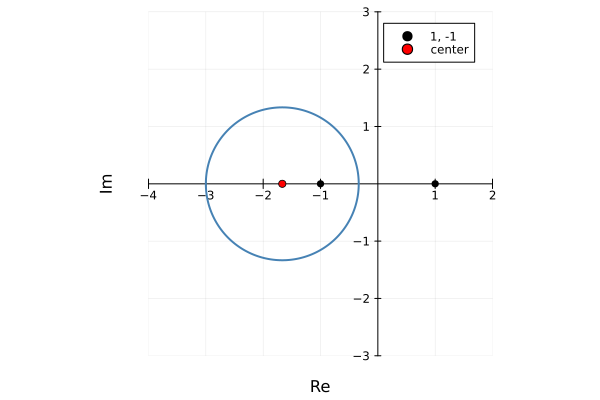

In [36]:
zplane(4; xlims=(-4, 2), ylims=(-3, 3))
zlocus!(F; color=:steelblue, lw=2)
zscatter!([1, -1]; color=:black, label="1, -1")
zscatter!([c]; color=:red, label="center")

# 検算：円周上の点で |z - 1| / |z + 1| = 2 になっているか
zs = [c + r * cis(t) for t in (0.3, 1.0, 2.0, 4.0)]
@show abs.(zs .- 1) ./ abs.(zs .+ 1)
plot!()

**いろいろな軌跡**

In [37]:
e1, F1 = locus("Abs[z - 1]^2 == Abs[z - I]^2")            # 2 点から等距離 → 垂直二等分線
e2, F2 = locus("Abs[z - (1 + I)]^2 == 4")                 # 点 1+i からの距離が 2 → 円
e3, F3 = locus("z Conjugate[z] + (1 - I) z + (1 + I) Conjugate[z] == 2")
circle_of(e3)
e4, F4 = locus("Re[z^2] == 1");                           # 双曲線

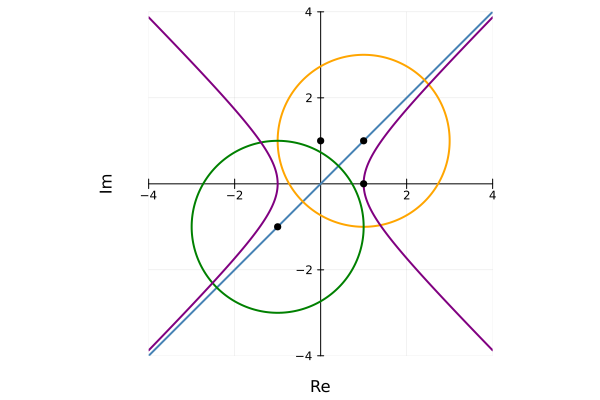

In [38]:
zplane(4)
zlocus!(F1; color=:steelblue, lw=2)
zlocus!(F2; color=:orange, lw=2)
zlocus!(F3; color=:green, lw=2)
zlocus!(F4; color=:purple, lw=2)
zscatter!([1, im, 1 + im, -1 - im]; color=:black, label="")

### 変換 $w = \dfrac1z$ による像

直線 $\mathrm{Re}\,z = 1$ 上の点 $z = 1 + ti$ を $w = \dfrac1z$ で移すと，円になります。  
Wolfram で $w$ の実部・虚部を $t$ の式で求め，$\left|w - \frac12\right|$ が一定であることを確かめます。

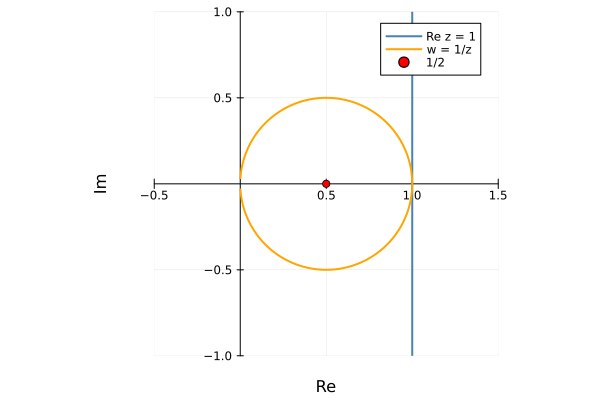

In [39]:
ww = calc("1/(1 + I t)")
calc("Abs[1/(1 + I t) - 1/2]^2"; then="Simplify")        # → 1/4（t によらない）なので，中心 1/2，半径 1/2 の円

wmap = to_function(ww, :t)                               # t -> w
ts = range(-30, 30; length=2001)

zplane(1.5; xlims=(-0.5, 1.5), ylims=(-1, 1))
vline!([1]; color=:steelblue, lw=2, label="Re z = 1")
zpath!(wmap.(ts); color=:orange, lw=2, label="w = 1/z")
zscatter!([1 // 2]; color=:red, label="1/2")

## 9. うまくいかないとき

- **接続エラー（`AssertionError: nextpacket(...)` など）**：Wolfram Engine のカーネル数上限に達しています。他のノートブックのカーネルや `wolframscript` を止めてから，Julia カーネルを再起動してください。
- **$(-1)^{2/3}$ のような形で返る**：`ComplexExpand[...]` で $a + bi$ の形にします（`calc`，`csolve` は自動でかけています）。
- **虚数単位**：Wolfram では大文字の `I`，Julia では `im`。Julia で `2im` は書けますが `sqrt(3)im` は `sqrt(3) * im` の意味です。
- **`ComplexExpand` は文字を実数とみなす**：$x, y, t$ などの文字は実数として展開されます。複素数の文字 $z$ は，`locus` のように $x + yi$ に置き換えてから展開します。
- **軌跡の条件**：絶対値は `Abs[z - 1]^2 == 4 Abs[z + 1]^2` のように 2 乗して書くと，根号のない方程式になります。

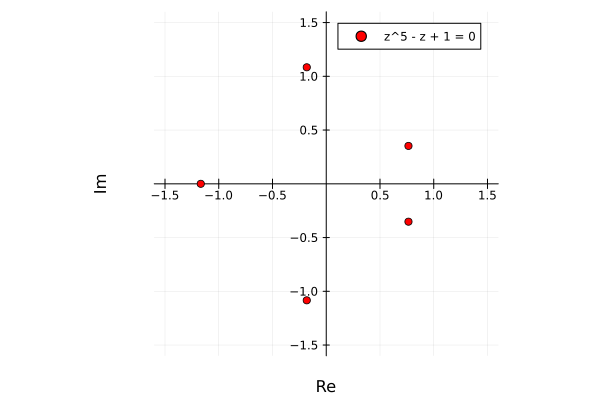

In [40]:
# 5 次以上で根号で表せない解は，数値で返す
_, zr = csolve("z^5 - z + 1 == 0")

zplane(1.6)
zscatter!(zr; color=:red, label="z^5 - z + 1 = 0")